# Statistical Analysis of Developer Pay and Job Satisfaction

**Objective:** Identify which factors (work setup, role type, experience and country) are linked to higher pay and job satisfaction among developers, using descriptive statistics and hypothesis testing.

**Dataset:** Stack Overflow Developer Survey 2025 | 49,191 respondents | 173 columns (16 selected) | includes pay, job satisfaction, experience, work setup, role type, country, and technologies used.

**Business Question:** Which factors are linked to higher pay and job satisfaction among tech workers, and what can HR do about work-from-home policy and pay structure?

**Questions and methods**
* Q1. Does pay differ by work setup? ANOVA
* Q2. Do managers earn more than individual contributors? t-test, 95% confidence interval
* Q3. Does job satisfaction differ by work setup? ANOVA, chi-square test
* Q4. How strongly are pay and satisfaction linked to experience? Correlation
* Q5. Does work setup still matter inside one country? ANOVA

## 1. Import and Setup
In this section, we load the required Python libraries, configure our global notebook display settings

In [1]:
# Core libraries for data handling and analysis
import numpy as np 
import pandas as pd

# Visualization libraries
import seaborn as sns
import matplotlib.pyplot as plt

# Statistical libraries
import scipy.stats as stats

# For keeping the size and bg color of chart consistent
sns.set_theme(style='white')
plt.rcParams['figure.figsize']=(12,6)

# Show all columns while previewing data (Useful as we have many columns)
pd.set_option('display.max_columns',None)

# File Path
raw_dataset = "../Data/Original/so_survey_2025.csv"


## 2. Load the Original Raw Dataset
First i look the whole original file

In [2]:
# Read the original file
raw = pd.read_csv(raw_dataset)

# How big it is ?
print(f"Rows (People): {raw.shape[0]}")
print(f"Columns (Questions): {raw.shape[1]}")

C:\Users\Sahil\AppData\Local\Temp\ipykernel_38956\1077197359.py:2: DtypeWarning: Columns (57: JobSatPoints_15_TEXT, 75: DatabaseHaveEntry, 93: DevEnvHaveEntry, 98: SOTagsHaveEntry, 99: SOTagsWant Entry, 106: OfficeStackWantEntry, 110: CommPlatformHaveEntr, 111: CommPlatformWantEntr, 133: SO_Actions_15_TEXT, 163: AIAgentOrchestration, 166: AIAgentObsWrite) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(raw_dataset)


Rows (People): 49191
Columns (Questions): 173


In [3]:
# Show the names of the all column
print(list(raw.columns))

['Unnamed: 0', 'ResponseId', 'MainBranch', 'Age', 'EdLevel', 'Employment', 'EmploymentAddl', 'WorkExp', 'LearnCodeChoose', 'LearnCode', 'LearnCodeAI', 'AILearnHow', 'YearsCode', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'PurchaseInfluence', 'TechEndorseIntro', 'TechEndorse_1', 'TechEndorse_2', 'TechEndorse_3', 'TechEndorse_4', 'TechEndorse_5', 'TechEndorse_6', 'TechEndorse_7', 'TechEndorse_8', 'TechEndorse_9', 'TechEndorse_13', 'TechEndorse_13_TEXT', 'TechOppose_1', 'TechOppose_2', 'TechOppose_3', 'TechOppose_5', 'TechOppose_7', 'TechOppose_9', 'TechOppose_11', 'TechOppose_13', 'TechOppose_16', 'TechOppose_15', 'TechOppose_15_TEXT', 'Industry', 'JobSatPoints_1', 'JobSatPoints_2', 'JobSatPoints_3', 'JobSatPoints_4', 'JobSatPoints_5', 'JobSatPoints_6', 'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9', 'JobSatPoints_10', 'JobSatPoints_11', 'JobSatPoints_13', 'JobSatPoints_14', 'JobSatPoints_15', 'JobSatPoints_16', 'JobSatPoints_15_TEXT', 'AIThreat', 'NewRole', 'ToolCountWork', 'To

**What I notice:** there are 173 questions. Most of them are about programming tools, AI and Stack Overflow habits. They are interesting, but they do not answer my question about **pay and satisfaction**. So I choose only the columns that do.

| Group | Columns | Why |
|---|---|---|
| **Outcomes** | `ConvertedCompYearly` , `JobSat` | Yearly pay in US dollor and job satisfaction from 0 to 10 |
| **Experience** | `WorkExp` , `YearsCode` | Work experience and years of coding |
| **Person** | `Age` ,`Country`, `EdLevel` | Pay depend strongly on this |
| **Work setup** | `RemoteWork`, `Employment`, `OrgSize`, `ICorPM` | Remote or office, job status, company size, manager or not |
| **Role and tools** | `DevType`, `Industry`, `LanguageHaveWorkedWith`, `DatabaseHaveWorkedWith` | Type of job, and technologies used |

I also keep `ResponseId`, a unique ID for each person.

In [4]:
# The list of the 16 columns to keep
keep = ["ResponseId", "ConvertedCompYearly", "JobSat", "WorkExp", "YearsCode",
        "Age", "Country", "EdLevel", "RemoteWork", "Employment", "OrgSize",
        "ICorPM", "DevType", "Industry",
        "LanguageHaveWorkedWith", "DatabaseHaveWorkedWith"]


df = pd.read_csv(raw_dataset,usecols=keep)


# Save it as smaller file
df.to_csv("../Data/Selected/so_survey_2025_selected.csv", index=False)

## 3. Load the Selected Data & First look

In [5]:
df = pd.read_csv("../Data/Selected/so_survey_2025_selected.csv")

In [6]:
# Show the first 5 rows
df.head()

,ResponseId,Age,EdLevel,Employment,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Industry,Country,LanguageHaveWorkedWith,DatabaseHaveWorkedWith,ConvertedCompYearly,JobSat
0,1,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,8.0,14.0,"Developer, mobile",20 to 99 employees,People manager,Remote,Fintech,Ukraine,Bash/Shell (all shells);Dart;SQL,Cloud Firestore;PostgreSQL,61256.0,10.0
1,2,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,2.0,10.0,"Developer, back-end",500 to 999 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",Retail and Consumer Services,Netherlands,Java,Dynamodb;MongoDB,104413.0,9.0
2,3,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",10.0,12.0,"Developer, front-end",NaN,NaN,NaN,Software Development,Ukraine,Dart;HTML/CSS;JavaScript;TypeScript,MongoDB;MySQL;PostgreSQL,53061.0,8.0
3,4,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,4.0,5.0,"Developer, back-end","10,000 or more employees",Individual contributor,Remote,Retail and Consumer Services,Ukraine,Java;Kotlin;SQL,NaN,36197.0,6.0
4,5,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",21.0,22.0,Engineering manager,NaN,NaN,NaN,Software Development,Ukraine,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...,Elasticsearch;Microsoft SQL Server;MySQL;Oracl...,60000.0,7.0


In [7]:
# Inspect datatype & non null count
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ResponseId              49191 non-null  int64  
 1   Age                     49191 non-null  str    
 2   EdLevel                 48149 non-null  str    
 3   Employment              48339 non-null  str    
 4   WorkExp                 42893 non-null  float64
 5   YearsCode               43042 non-null  float64
 6   DevType                 43680 non-null  str    
 7   OrgSize                 34178 non-null  str    
 8   ICorPM                  33243 non-null  str    
 9   RemoteWork              33780 non-null  str    
 10  Industry                33642 non-null  str    
 11  Country                 35437 non-null  str    
 12  LanguageHaveWorkedWith  31671 non-null  str    
 13  DatabaseHaveWorkedWith  25550 non-null  str    
 14  ConvertedCompYearly     23947 non-null  float64
 

In [8]:
# Statistical summary
df.describe().round(2)

,ResponseId,WorkExp,YearsCode,ConvertedCompYearly,JobSat
count,49191.00,42893.00,43042.00,23947.00,26670.0
mean,24596.00,13.37,16.57,101761.54,7.2
std,14200.36,10.80,11.79,461756.90,2.0
min,1.00,1.00,1.00,1.00,0.0
25%,12298.50,5.00,8.00,38171.00,6.0
50%,24596.00,10.00,14.00,75320.00,8.0
75%,36893.50,20.00,24.00,120596.00,8.0
max,49191.00,100.00,100.00,50000000.00,10.0


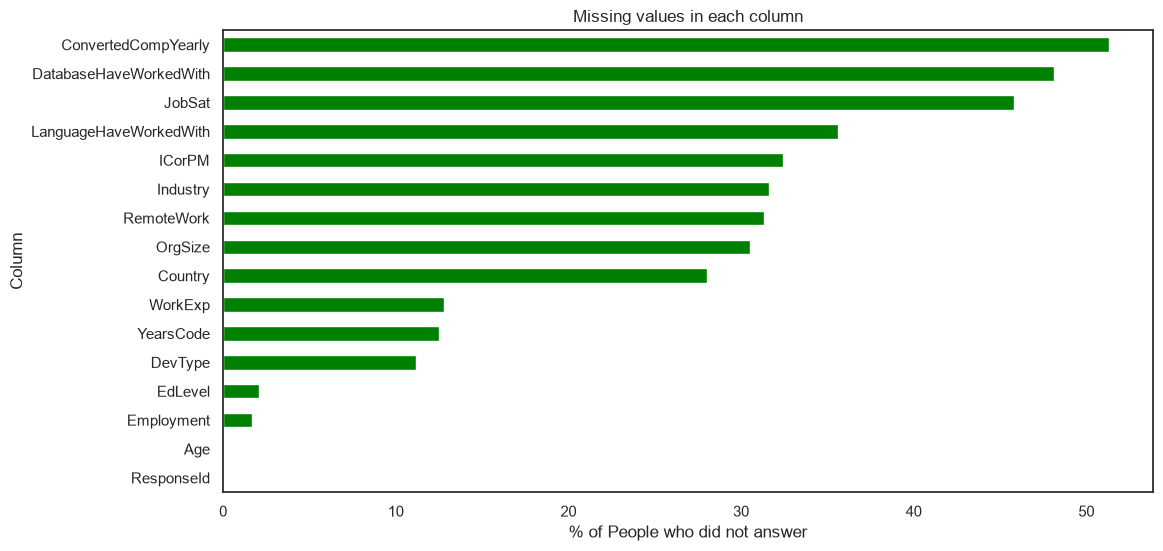

In [9]:
# Check the percentage of null values
missing_pct = (df.isnull().mean() * 100).round(1)
missing_pct = missing_pct.sort_values()

missing_pct.plot(kind='barh',color="green")
plt.title("Missing values in each column")
plt.xlabel("% of People who did not answer")
plt.ylabel("Column",rotation=90)
plt.savefig("../Images/01_missing_values.png", bbox_inches="tight")
plt.show()

**Observations :**
* Pay (`ConvertedCompYearly`) and job satisfaction (`JobSat`) are among the columns with the most missing values, and they are the two I care about most. I will not fill them with made-up values, because inventing pay or satisfaction could distort the results. Instead:
  * **Pay:** rows with no pay are removed, because I cannot study pay without it. I count how many people I lose at each step.
  * **Job satisfaction:** missing values are **kept as missing** in the main dataset. Only the analyses that use satisfaction ignore those rows, so pay-only analysis keeps all its data.
* Text columns like `Age` and `OrgSize` have longer, wordy string formats (like "20 to 99 employees" or "25-34 years old"), so need to clean those up later to make the values look shorter and cleaner for charts.

## 4. Data cleaning

**rules, and why:**

* **Keep only people who are Employed** — Students and retirees do not have a normal yearly pay.
* **Remove people with no pay** — I cannot study pay without pay.
* **Keep pay between $1,000 and $500,000** — Smaller values are typing mistakes and the maximum in the raw data is $33.5 million (outliers).
* **Group the work setup into simple groups** — The original labels are very long.

#### 4.1 Removing duplicates

In [10]:
# Count duplicate rows
print("Duplicate IDs:", df['ResponseId'].duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates(subset='ResponseId')

Duplicate IDs: 0


#### 4.2 Keeping only employed people

In [11]:
# Keep only Employed peoples
df = df[df['Employment'] =='Employed'].copy()

print("Rows after keeping employed:", len(df))

Rows after keeping employed: 33750


#### 4.3 Check Sample Bias

In [12]:
# Split employees into those who give their pay & those who don't
answered = df[df['ConvertedCompYearly'].notnull()]
not_answered = df[df['ConvertedCompYearly'].isnull()]

print(f"People who give their pay: {len(answered)}")
print(f"People who did not give their pay: {len(not_answered)}")

# Compare avg experience
print(f"Average experience (Answered): {(answered['WorkExp'].mean().round(1))}")
print(f"Average experience (Not Answered): {(not_answered['WorkExp'].mean().round(1))}")

# Compare share of remote workers
print(f"% of remote workers (Answered): {round((answered['RemoteWork']== 'Remote').mean() * 100,1)}")
print(f"% of remote workers (Not Answered): {round((not_answered['RemoteWork']== 'Remote').mean() * 100,1)}")



People who give their pay: 19500
People who did not give their pay: 14250
Average experience (Answered): 13.2
Average experience (Not Answered): 12.2
% of remote workers (Answered): 32.2
% of remote workers (Not Answered): 20.4


  **Conclusion:**
  * **Experience:** Similar between the two groups (13.2 vs. 12.2 years).
  * **Remote work:** Clearly different (32.2% vs. 20.4%). Remote workers report pay more often.
  * **Verdict:** Missing pay is not completely random, so my results describe developers who report their pay. I keep this as a limitation.

#### 4.4 Remove people with no pay

In [13]:

df = df.dropna(subset=['ConvertedCompYearly'])

# Look at the pay column BEFORE removing outliers
print(df["ConvertedCompYearly"].describe())

print("Rows after removing missing pay:", len(df))

count    1.950000e+04
mean     1.025096e+05
std      3.440871e+05
min      1.000000e+00
25%      4.385400e+04
50%      7.889000e+04
75%      1.243732e+05
max      3.355272e+07
Name: ConvertedCompYearly, dtype: float64
Rows after removing missing pay: 19500


**Look at the minimum and the maximum:** pay goes from about $1 up to $33.5 million. These are clearly typing mistakes (outliers). I keep only pay between $1,000 and $500,000.

In [14]:
# Keep only pay between 1,000 and 500,000 dollars
df = df[(df['ConvertedCompYearly'] >= 1000) & (df['ConvertedCompYearly'] <= 500000)].copy()

# Look at the pay column AFTER removing outliers
print(df["ConvertedCompYearly"].describe())

print("Rows after removing pay outliers:", len(df))

count     18953.000000
mean      93852.684219
std       71256.393553
min        1000.000000
25%       46406.000000
50%       80000.000000
75%      124136.000000
max      500000.000000
Name: ConvertedCompYearly, dtype: float64
Rows after removing pay outliers: 18953


**Explanation:** The raw pay column had values from $1 up to $33.5 million, which are mistakes. I kept pay between $1,000 and $500,000.

#### 4.5 Standardizing lables

In [15]:
# Remove " years old" from the age labels (25-34 years old -> 25-34)
df['Age'] = df['Age'].replace({' years old':'',
                               ' years or older':'+',
                               'Prefer not to say':np.nan},regex=True)

# Check the result
df['Age'].value_counts(dropna=False)

Age
25-34    7209
35-44    6197
45-54    2678
18-24    1751
55-64     980
65+       129
NaN         9
Name: count, dtype: int64

In [16]:
# Keep only the text before the bracket (Master’s degree (M.A., ...) -> Master’s degree)
df['EdLevel'] = df['EdLevel'].str.split(' (',regex=False).str[0]

# Check the result
df['EdLevel'].value_counts(dropna=False)

EdLevel
Bachelor’s degree                                         8551
Master’s degree                                           5573
Some college/university study without earning a degree    2045
Professional degree                                       1108
Secondary school                                           798
Associate degree                                           637
Other                                                      160
Primary/elementary school                                   68
NaN                                                         13
Name: count, dtype: int64

In [17]:
# Shorten the company size labels
df['OrgSize'] = df['OrgSize'].replace({
    'Just me - I am a freelancer, sole proprietor, etc.': 'Just me',
    'Less than 20 employees': 'Less than 20',
    '20 to 99 employees': '20-99',
    '100 to 499 employees': '100-499',
    '500 to 999 employees': '500-999',
    '1,000 to 4,999 employees': '1,000-4,999',
    '5,000 to 9,999 employees': '5,000-9,999',
    '10,000 or more employees': '10,000+',
    'I don’t know': np.nan    
})

# Check the result
df['OrgSize'].value_counts(dropna=False)

OrgSize
20-99           3976
100-499         3782
10,000+         2993
Less than 20    2777
1,000-4,999     2582
500-999         1498
5,000-9,999      997
NaN              244
Just me          104
Name: count, dtype: int64

In [18]:
# Standardize work setup categories into 4 groups (combining hybrid types)
df['RemoteWork'] = df['RemoteWork'].replace({
    'Remote':'Remote',
    'In-person':'In-person',
    'Hybrid (some in-person, leans heavy to flexibility)':'Hybrid',
    'Hybrid (some remote, leans heavy to in-person)':'Hybrid',
    'Your choice (very flexible, you can come in when you want or just as needed)':'Flexible',
})
# Check the result
df['RemoteWork'].value_counts(dropna=False)


RemoteWork
Hybrid       7474
Remote       6078
In-person    2881
Flexible     2427
NaN            93
Name: count, dtype: int64

In [19]:
df.head()

,ResponseId,Age,EdLevel,Employment,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Industry,Country,LanguageHaveWorkedWith,DatabaseHaveWorkedWith,ConvertedCompYearly,JobSat
0,1,25-34,Master’s degree,Employed,8.0,14.0,"Developer, mobile",20-99,People manager,Remote,Fintech,Ukraine,Bash/Shell (all shells);Dart;SQL,Cloud Firestore;PostgreSQL,61256.0,10.0
1,2,25-34,Associate degree,Employed,2.0,10.0,"Developer, back-end",500-999,Individual contributor,Hybrid,Retail and Consumer Services,Netherlands,Java,Dynamodb;MongoDB,104413.0,9.0
3,4,35-44,Bachelor’s degree,Employed,4.0,5.0,"Developer, back-end","10,000+",Individual contributor,Remote,Retail and Consumer Services,Ukraine,Java;Kotlin;SQL,NaN,36197.0,6.0
7,8,35-44,Professional degree,Employed,22.0,30.0,"Architect, software or solutions",Less than 20,People manager,Remote,Software Development,Ukraine,Bash/Shell (all shells);HTML/CSS;JavaScript;Py...,MongoDB;PostgreSQL;SQLite,72000.0,6.0
8,9,25-34,Bachelor’s degree,Employed,9.0,15.0,Data engineer,"5,000-9,999",Individual contributor,Remote,Banking/Financial Services,Ukraine,Java;Python;Scala,Cassandra;Databricks SQL;DuckDB;Dynamodb;Maria...,70000.0,8.0


#### 4.6 Create a new column


In [20]:
# Check summary statistics to spot skewness (Notice how Mean is much higher than Median/50%)
print(df['ConvertedCompYearly'].describe())

# Check the exact skewness value
print('Skewness:', df['ConvertedCompYearly'].skew())

count     18953.000000
mean      93852.684219
std       71256.393553
min        1000.000000
25%       46406.000000
50%       80000.000000
75%      124136.000000
max      500000.000000
Name: ConvertedCompYearly, dtype: float64
Skewness: 1.606168218748616


In [21]:
# Create the natural logarithm of pay
df['log_pay'] = np.log(df['ConvertedCompYearly'])

# Count the languages and databases used
df['language_count'] = df['LanguageHaveWorkedWith'].str.count(';') + 1
df['database_count'] = df['DatabaseHaveWorkedWith'].str.count(';') + 1

# Check the new columns
df[["ConvertedCompYearly", "log_pay", "language_count", "database_count"]].head()

,ConvertedCompYearly,log_pay,language_count,database_count
0,61256.0,11.022817,3.0,2.0
1,104413.0,11.556109,1.0,2.0
3,36197.0,10.496732,3.0,NaN
7,72000.0,11.184421,6.0,3.0
8,70000.0,11.156251,3.0,10.0


#### 4.7 Handling Mssing Values

In [22]:
# Check the percentage & count of missing values for each column
missing_values = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

print(missing_values)

                        Missing_Count  Missing_Percentage (%)
ResponseId                          0                0.000000
Age                                 9                0.047486
EdLevel                            13                0.068591
Employment                          0                0.000000
WorkExp                           193                1.018308
YearsCode                          70                0.369335
DevType                             0                0.000000
OrgSize                           244                1.287395
ICorPM                            285                1.503720
RemoteWork                         93                0.490687
Industry                           29                0.153010
Country                             0                0.000000
LanguageHaveWorkedWith           1280                6.753548
DatabaseHaveWorkedWith           4203               22.175909
ConvertedCompYearly                 0                0.000000
JobSat  

Droping rows where columns have missing values (under 5% missing rate)

In [23]:
df = df.dropna(subset=['Age', 'EdLevel', 'WorkExp', 
                       'YearsCode','OrgSize','ICorPM',
                       'RemoteWork','Industry'])

print("Rows after dropping missing values:", len(df))

Rows after dropping missing values: 18153


In [24]:
# Save the clean data (used later for SQL and Tableau)
df.to_csv("../Data/Cleaned/so_survey_2025_clean.csv", index=False)

## 5. Exploratory Data Analysis (EDA)
#### 5.1 Summary statistics of pay

In [25]:
pay =df['ConvertedCompYearly']

# Calculate the central tendency
print('Mean:',round(pay.mean()))
print('Median:',round(pay.median()))
print('Mode:',pay.mode()[0])

# Calculate the dispersion
print('Standard Deviation:',round(pay.std()))
print('Variance:',round(pay.var()))
print('Range:',pay.max() - pay.min())

# Calculate the skewness
print('Skewness:',round(pay.skew(),2))



Mean: 94785
Median: 81210
Mode: 69609.0
Standard Deviation: 71214
Variance: 5071433875
Range: 499000.0
Skewness: 1.6


In [26]:
# Print the five number summary 
print(pay.describe())

# Calculate the IQR
q1 = pay.quantile(0.25)
q3 = pay.quantile(0.75)
print('IQR:',q3-q1)

count     18153.000000
mean      94784.670578
std       71214.000557
min        1000.000000
25%       46406.000000
50%       81210.000000
75%      125000.000000
max      500000.000000
Name: ConvertedCompYearly, dtype: float64
IQR: 78594.0


#### 5.2 Distribution of Pay

Skewness of Pay: 1.6
Skewness of log(pay) -1.38


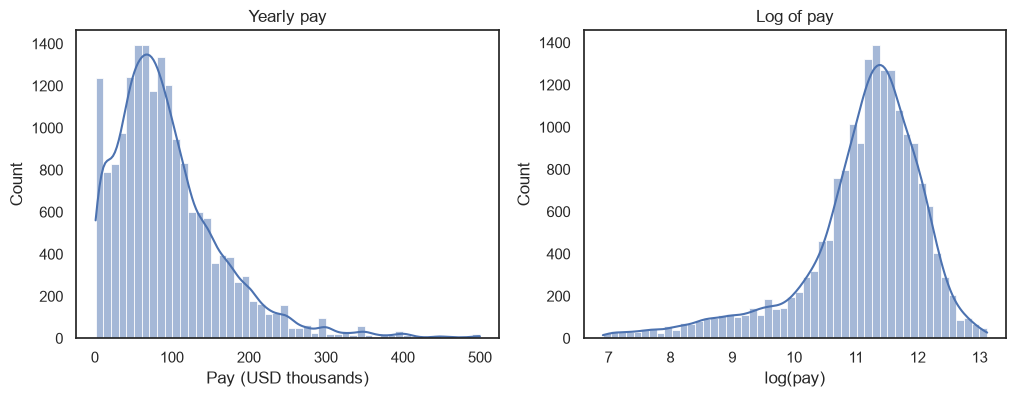

In [27]:
plt.figure(figsize=(12,4))

# Plot pay
plt.subplot(1,2,1)
sns.histplot(pay / 1000,bins=50,kde=True)
plt.title('Yearly pay')
plt.xlabel('Pay (USD thousands)')

# Plot log of pay
plt.subplot(1,2,2)
sns.histplot(df['log_pay'],bins=50,kde=True)
plt.title('Log of pay')
plt.xlabel('log(pay)')

# Compare Skewness
print('Skewness of Pay:',round(pay.skew(),2))
print('Skewness of log(pay)',round(df['log_pay'].skew(),2))
plt.savefig("../Images/02_distribution_of_pay.png", bbox_inches="tight")
plt.show()

Pay is right-skewed (a few very high salaries pull the mean above the median). The log transformation compresses the upper tail but introduces a moderate left skew (-1.38) because some respondents report low salaries. Despite this shift, the large sample size and Central Limit Theorem strongly support the continued use of t-tests and ANOVA for our analysis.

#### 5.3 Job Satisfaction

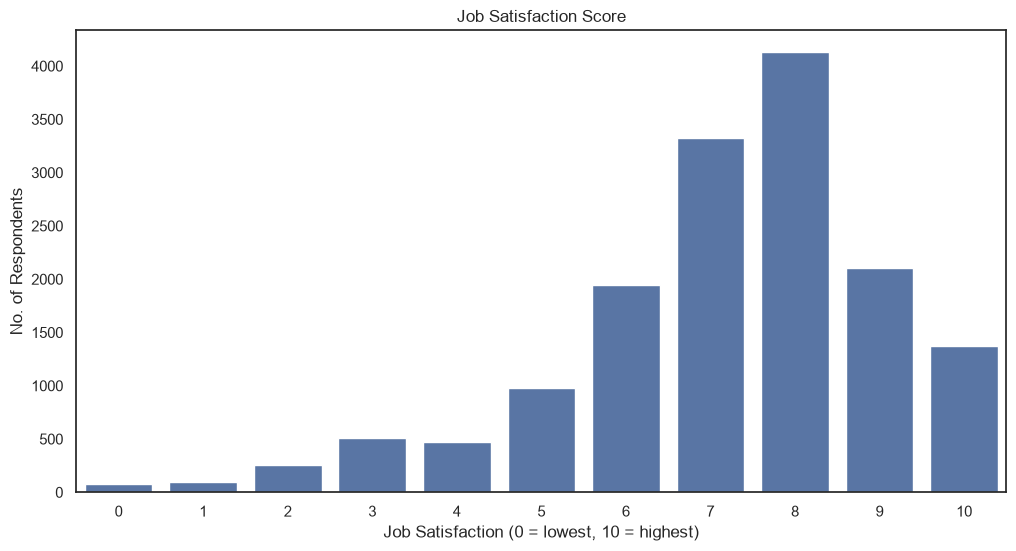

In [28]:
# Counting the respondents for each score
sns.countplot(x=df['JobSat'].dropna().astype(int))
plt.title('Job Satisfaction Score')
plt.ylabel('No. of Respondents')
plt.xlabel('Job Satisfaction (0 = lowest, 10 = highest)')
plt.savefig("../Images/03_job_satisfaction.png", bbox_inches="tight")
plt.show()


#### 5.4 Respondent's Profile

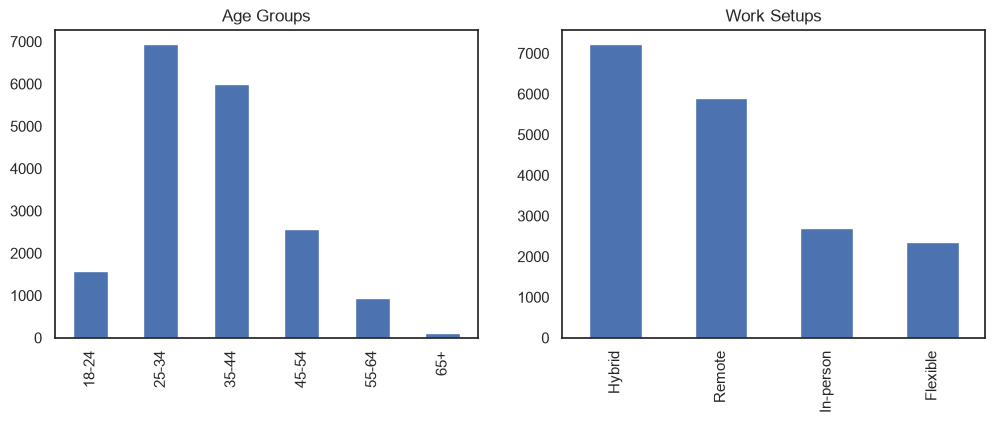

In [29]:
plt.figure(figsize=(12,4))

# Plot the Age
plt.subplot(1,2,1)
df["Age"].value_counts().sort_index().plot(kind="bar")
plt.title('Age Groups')
plt.ylabel('')
plt.xlabel('')

# Plot the remotework
plt.subplot(1,2,2)
df["RemoteWork"].value_counts().plot(kind="bar")
plt.title('Work Setups')
plt.ylabel('')
plt.xlabel('')

plt.savefig("../Images/04_age_and_work_setup.png", bbox_inches="tight")
plt.show()


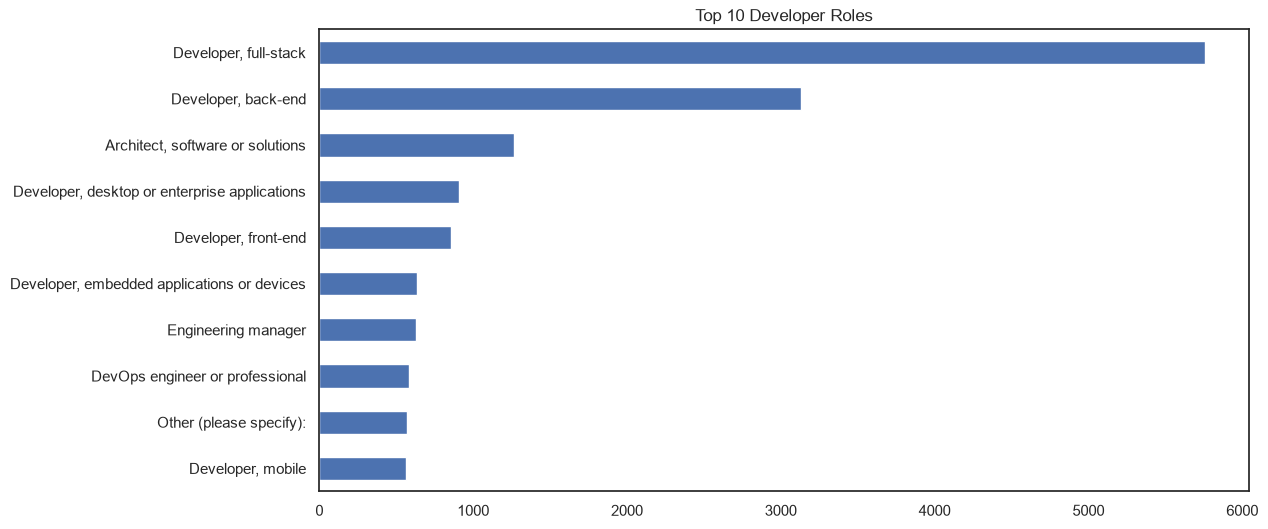

In [30]:
# Plot the 10 most common developer roles
df['DevType'].value_counts().head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Developer Roles')
plt.ylabel('')
plt.savefig("../Images/05_top_10_developer_roles.png", bbox_inches="tight")
plt.show()

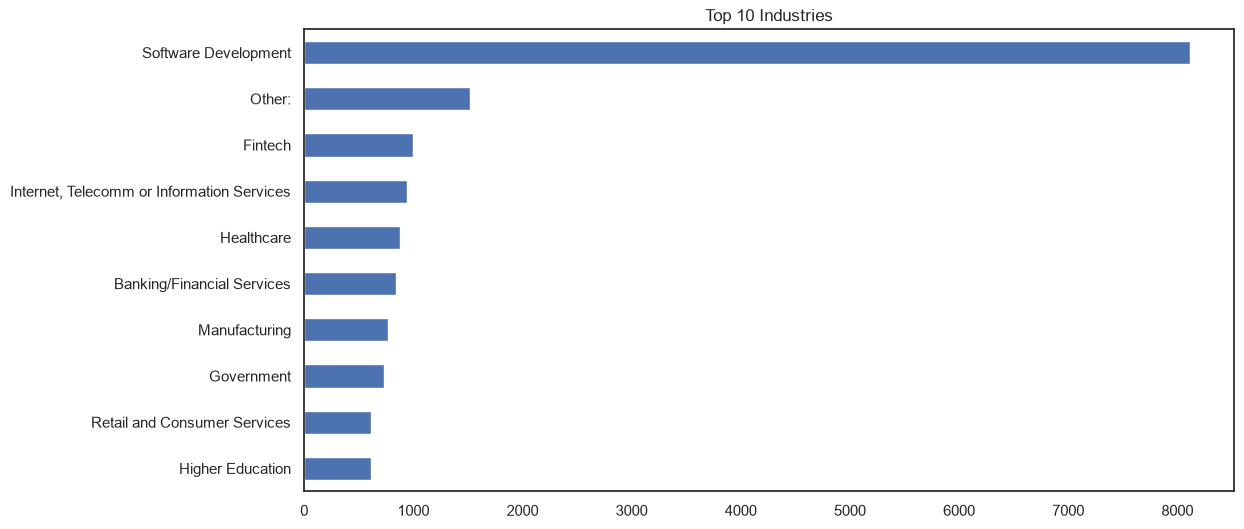

In [31]:
# plot the 10 most common industries
df['Industry'].value_counts().head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Industries')
plt.ylabel('')
plt.savefig("../Images/06_top_10_industries.png", bbox_inches="tight")
plt.show()

#### 5.5 Median Pay by Group

RemoteWork
Flexible     80984.0
Hybrid       80000.0
In-person    52207.0
Remote       95132.0
Name: ConvertedCompYearly, dtype: float64


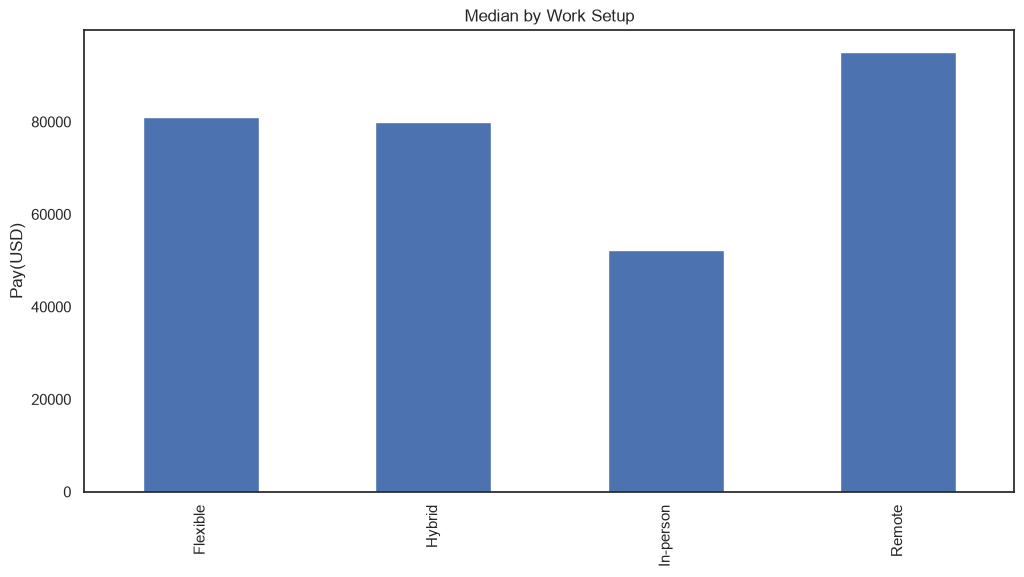

In [32]:
# Calculate the median by Work Setup
median_by_worksetup= df.groupby('RemoteWork')['ConvertedCompYearly'].median()
print(median_by_worksetup)

# Plot the median
median_by_worksetup.plot(kind='bar')
plt.title('Median by Work Setup')
plt.ylabel('Pay(USD)')
plt.xlabel('')
plt.savefig("../Images/07_median_by_work_setup.png", bbox_inches="tight")
plt.show()

ICorPM
Individual contributor    78890.0
People manager            93611.0
Name: ConvertedCompYearly, dtype: float64


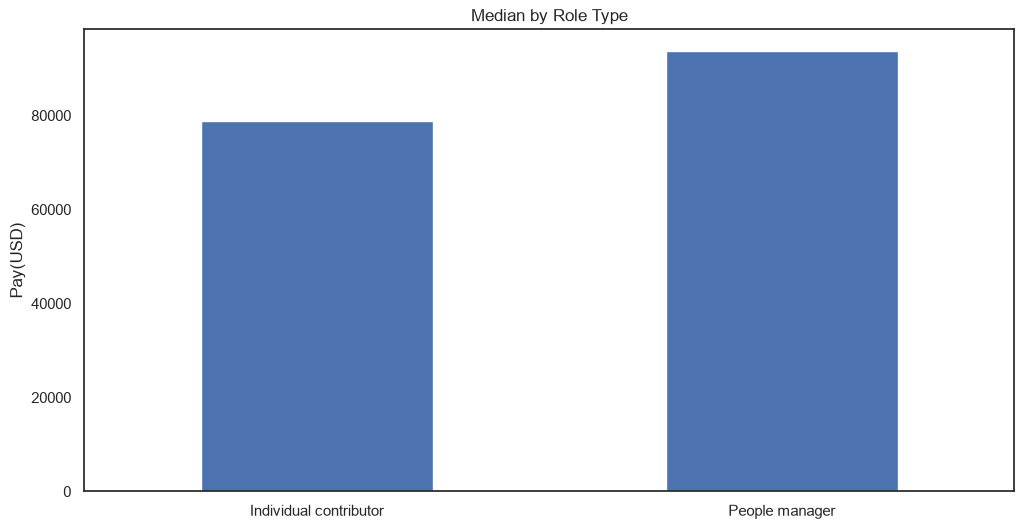

In [33]:
# Calculate the median pay by role type
median_by_role = df.groupby('ICorPM')['ConvertedCompYearly'].median()
print(median_by_role)

# Plot the median
median_by_role.plot(kind='bar')
plt.title('Median by Role Type')
plt.ylabel('Pay(USD)')
plt.xlabel('')
plt.xticks(rotation=0)
plt.savefig("../Images/08_median_by_role_type.png", bbox_inches="tight")
plt.show()

OrgSize
Just me          34804.0
Less than 20     60328.0
20-99            72192.0
100-499          81685.0
500-999          81685.0
1,000-4,999      87011.0
5,000-9,999      90781.5
10,000+         104000.0
Name: ConvertedCompYearly, dtype: float64


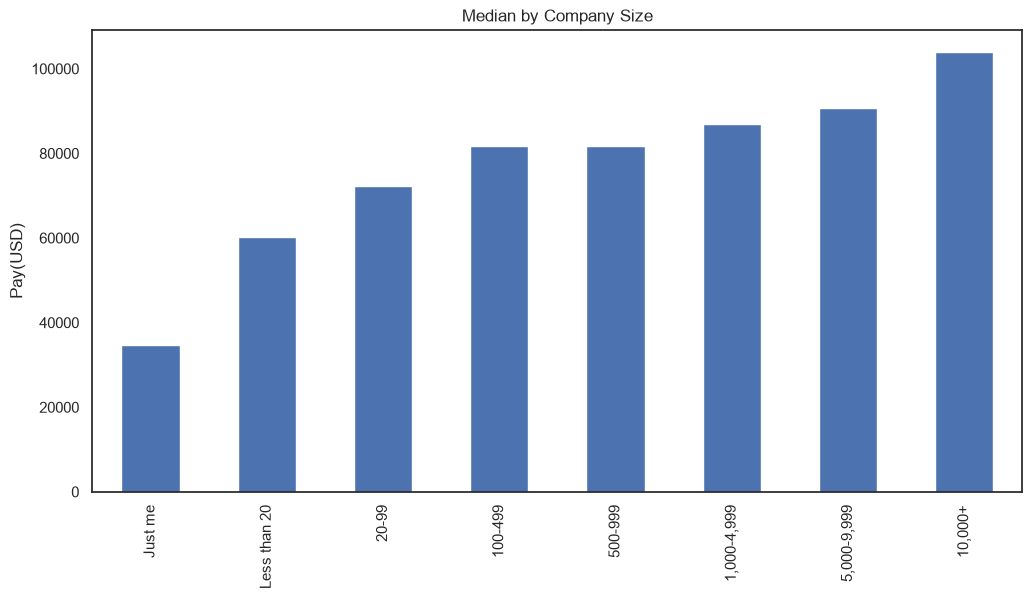

In [34]:
# Define the order of the company size
size_order = ["Just me", "Less than 20", "20-99", "100-499", "500-999",
              "1,000-4,999", "5,000-9,999", "10,000+"]

# Calculate the median pay by company size and apply order
median_by_company_size = df.groupby('OrgSize')['ConvertedCompYearly'].median().reindex(size_order)
print(median_by_company_size)

# Plot the result
median_by_company_size.plot(kind='bar')
plt.title('Median by Company Size')
plt.ylabel('Pay(USD)')
plt.xlabel('')
plt.savefig("../Images/09_median_by_company_size.png", bbox_inches="tight")
plt.show()

EdLevel
Secondary school                                          61756.0
Other                                                     63226.0
Primary/elementary school                                 64995.0
Associate degree                                          73023.5
Some college/university study without earning a degree    74249.0
Master’s degree                                           81210.0
Bachelor’s degree                                         81685.0
Professional degree                                       92812.0
Name: ConvertedCompYearly, dtype: float64


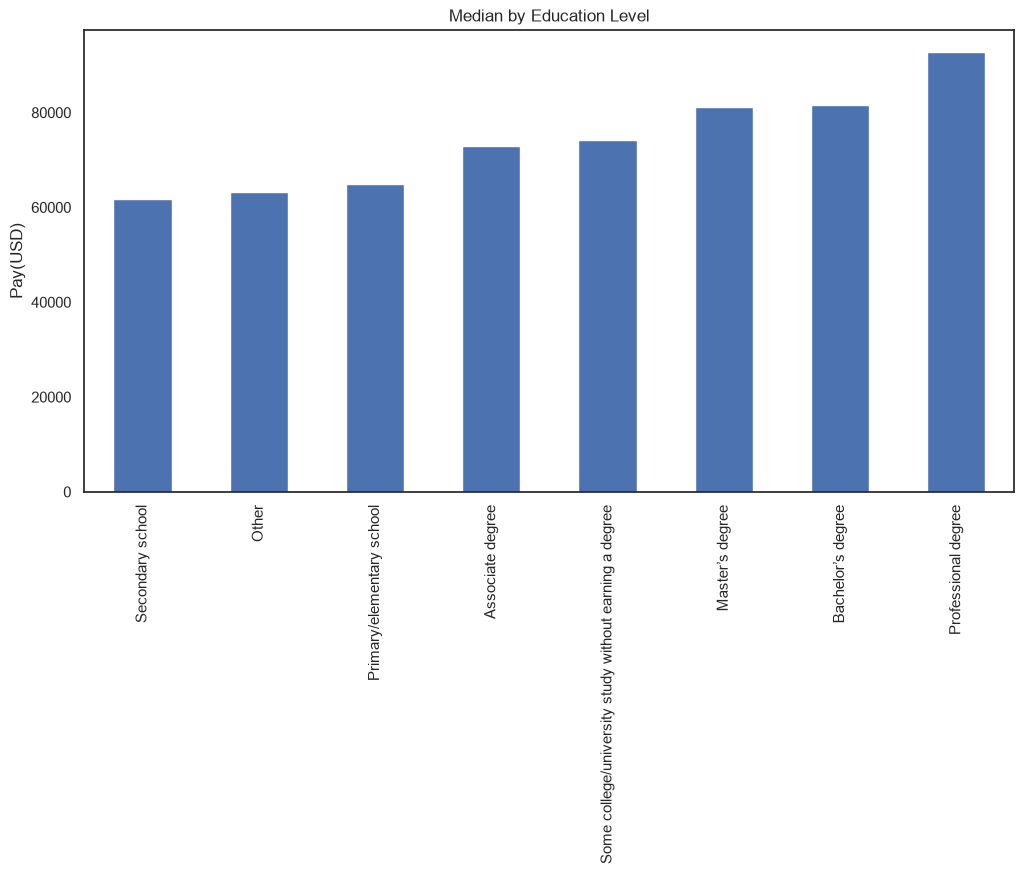

In [35]:
# calculate the median by education level ( lowest to highest)
median_by_edu = df.groupby('EdLevel')['ConvertedCompYearly'].median().sort_values()
print(median_by_edu)

# Plot the result
median_by_edu.plot(kind='bar')
plt.title('Median by Education Level')
plt.ylabel('Pay(USD)')
plt.xlabel('')
plt.savefig("../Images/10_median_by_education_level.png", bbox_inches="tight")
plt.show()


#### 5.6 Pay by Country

Country
India                                                    19761.0
Ukraine                                                  29958.0
Brazil                                                   31856.5
Italy                                                    48146.0
France                                                   61488.0
Netherlands                                              81210.0
Germany                                                  84691.0
Canada                                                   91198.0
United Kingdom of Great Britain and Northern Ireland     95299.0
United States of America                                150000.0
Name: ConvertedCompYearly, dtype: float64


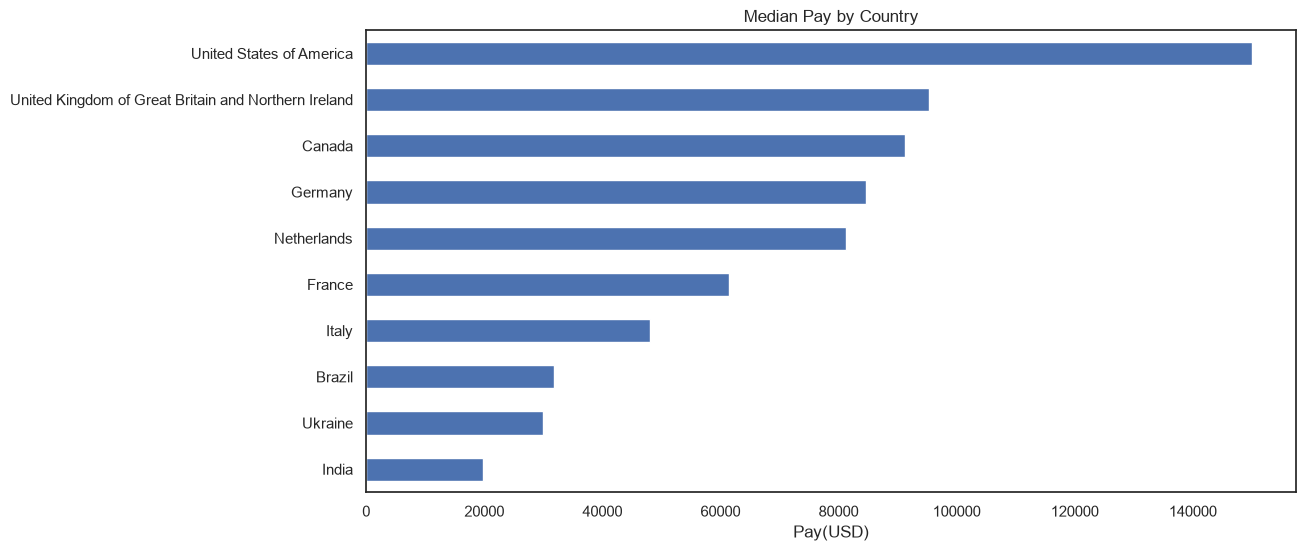

In [36]:
# Find the 10 countries with most respondents
top10 = df['Country'].value_counts().head(10).index
# Keep only respondents from these countries
top_df = df[df['Country'].isin(top10)]

# Calculate the median pay by country
median_by_country = top_df.groupby('Country')['ConvertedCompYearly'].median().sort_values(ascending=True)
print(median_by_country)

# Plot the results
median_by_country.plot(kind='barh')
plt.title('Median Pay by Country')
plt.ylabel('')
plt.xlabel('Pay(USD)')
plt.savefig("../Images/11_median_by_countries_with_most_respondents.png", bbox_inches="tight")
plt.show()


#### 5.7 Box Plot by Pay by Work Setup

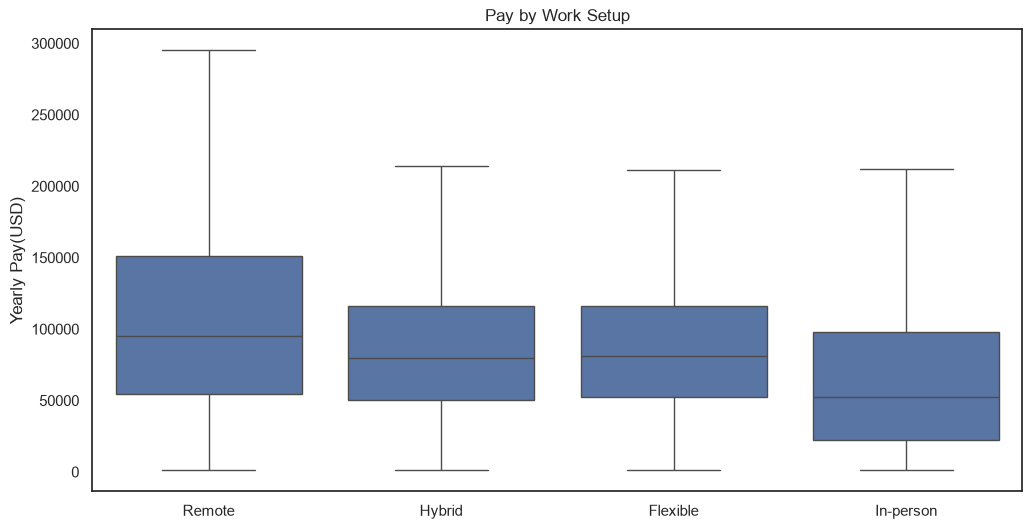

In [37]:
# Plot pay by work setup
sns.boxplot(x=df['RemoteWork'],y=df['ConvertedCompYearly'],data=df,showfliers=False)
plt.title('Pay by Work Setup')
plt.ylabel('Yearly Pay(USD)')
plt.xlabel('')
plt.savefig("../Images/12_pay_by_work_setup.png", bbox_inches="tight")
plt.show()


#### 5.8 Covariance & Correlation

In [38]:
# calculate the covariance & correlation between experience and log pay
print('covariance:',round(df['WorkExp'].cov(df['log_pay']),2))
print('correlation:',round(df['WorkExp'].corr(df['log_pay']),2))

covariance: 3.53
correlation: 0.37


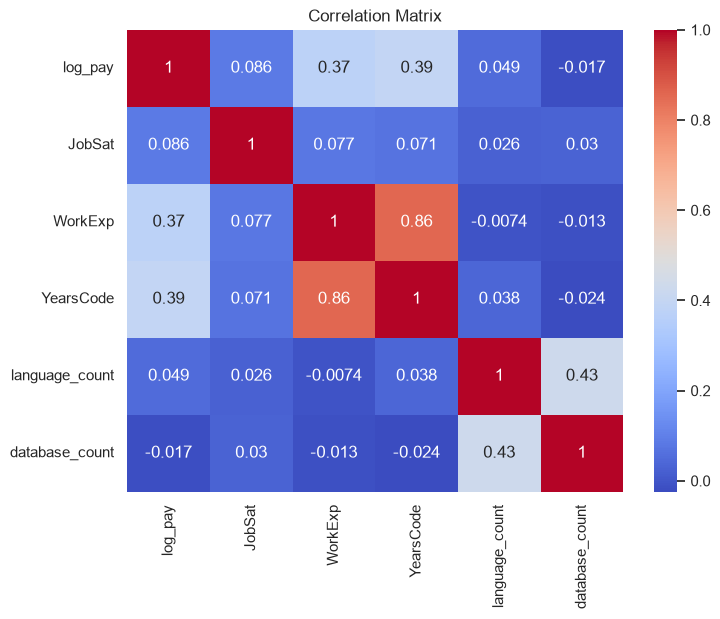

In [39]:
# Calculate the correlation matrix
corr = df[["log_pay", "JobSat", "WorkExp", "YearsCode", "language_count", "database_count"]].corr()

# Plot the heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title('Correlation Matrix')
plt.savefig("../Images/13_correlation_matrix.png", bbox_inches="tight")
plt.show()

## 6. Hypothesis Testing
* **Significance level:** alpha = 0.05. H0 is rejected when the p-value is below 0.05.
* **Log pay:** all pay tests use `log_pay`. A difference in log pay converts to a percentage difference in pay with `(np.exp(difference) - 1) * 100`.
* **Type 1 error:** a false alarm. When several comparisons are run together, a stricter alpha (0.05 divided by the number of comparisons) is used.


#### Q1: Does Pay Differ by Work Setup?

* **H0:** average log pay is the same for all work setups.
* **H1:** at least one work setup has a different average log pay.
* **Test:** one-way ANOVA. Assumptions: independent respondents, approximately normal log pay (see 5.2), similar standard deviations across groups.

In [40]:
# Create one group of log pay values per work setup
remote = df[df['RemoteWork'] == 'Remote']['log_pay']
hybrid = df[df['RemoteWork'] == 'Hybrid']['log_pay']
flexible = df[df['RemoteWork'] == 'Flexible']['log_pay']
in_person = df[df['RemoteWork'] == 'In-person']['log_pay']

# Count the respondents in each group
print("Respondents:", len(remote), len(hybrid), len(in_person), len(flexible))

# Check the equal spread assumption (the largest should be less than 2 times the smallest)
print("Std dev:", round(remote.std(), 2), round(hybrid.std(), 2), round(in_person.std(), 2), round(flexible.std(), 2))

Respondents: 5895 7218 2693 2347
Std dev: 1.04 0.9 1.18 0.83


In [41]:
# Run the ANOVA test
f_stat,p_q1 = stats.f_oneway(remote,hybrid,in_person,flexible)
print('F statistic:',round(f_stat,2))
print('p-value:',round(p_q1 ,4),'(0.0 means below 0.0001)')

# print the decision
if p_q1 < 0.05:
    print('Reject the H0: at least one work setup has different pay.')
else:
    print('Fail to reject H0: no clear difference in pay')

# Print the median pay for each work setup to see the real-world direction of the differences
print(df.groupby('RemoteWork')['ConvertedCompYearly'].median())

F statistic: 241.22
p-value: 0.0 (0.0 means below 0.0001)
Reject the H0: at least one work setup has different pay.
RemoteWork
Flexible     80984.0
Hybrid       80000.0
In-person    52207.0
Remote       95132.0
Name: ConvertedCompYearly, dtype: float64


In [42]:
# Calculate the stricter alpha for 3 comparizons
alpha_strict = 0.05 / 3

# Run the t-tests against In-person (equal_var=False allows different spreads)
t1,p1 = stats.ttest_ind(remote, in_person,equal_var=False)
t2,p2 = stats.ttest_ind(hybrid, in_person,equal_var=False)
t3,p3 = stats.ttest_ind(flexible,in_person,equal_var=False)

# Converting diff in log pay into percentage difference
d1 = (np.exp(remote.mean() - in_person.mean()) - 1 ) * 100
d2 = (np.exp(hybrid.mean() - in_person.mean()) - 1 ) * 100
d3 = (np.exp(flexible.mean() - in_person.mean()) - 1 ) * 100

# Print the results
print("Remote vs In-person:   difference =", round(d1, 1), "% | p =", round(p1, 4), "| significant:", p1 < alpha_strict)
print("Hybrid vs In-person:   difference =", round(d2, 1), "% | p =", round(p2, 4), "| significant:", p2 < alpha_strict)
print("Flexible vs In-person: difference =", round(d3, 1), "% | p =", round(p3, 4), "| significant:", p3 < alpha_strict)

Remote vs In-person:   difference = 82.2 % | p = 0.0 | significant: True
Hybrid vs In-person:   difference = 62.8 % | p = 0.0 | significant: True
Flexible vs In-person: difference = 67.5 % | p = 0.0 | significant: True


**Summary:** Pay differs by work setup (ANOVA, F = 241.22, p < 0.0001). Median pay is $95,132 for remote, $80,000 for hybrid, $80,984 for flexible and $52,207 for in-person workers. Compared with in-person workers, average pay is 82.2% higher for remote, 62.8% for hybrid and 67.5% for flexible workers. Remote vs In-person, Hybrid vs In-person, and Flexible vs In-person are all statistically significant. These are associations and do not show that work setup causes the pay difference.

#### Q2: Do people managers earn more than individual contributors?

* **H0:** managers and individual contributors have the same average (log) pay.
* **H1:** their average pay is different.
* **Test:** t-test, plus a **95% confidence interval** for the difference.

In [43]:
# Create two groups of log pay values by ICorPM
pm = df[df['ICorPM'] == 'People manager']['log_pay']
ic = df[df['ICorPM'] == 'Individual contributor']['log_pay']

# Check counts
print('Individual Contributers:',len(ic))
print('People manager:',len(pm))

Individual Contributers: 15466
People manager: 2687


In [44]:
# Run t test
t_stat,p_q2 = stats.ttest_ind(pm, ic, equal_var=False)
print('t statistics:',round(t_stat,2))
print('p value:',round(p_q2,4))

# print the decision
if p_q2 < 0.05:
    print('Reject the H0: Average pay is different')
else:
    print('Fail to reject the H0: No clear difference')

# Print the median pay for each work setup to see the real-world direction of the differences
print(df.groupby('ICorPM')['ConvertedCompYearly'].median())

t statistics: 7.05
p value: 0.0
Reject the H0: Average pay is different
ICorPM
Individual contributor    78890.0
People manager            93611.0
Name: ConvertedCompYearly, dtype: float64


In [45]:
# 95% confidence interval for the difference in average log pay
diff = pm.mean() - ic.mean()
se = np.sqrt(pm.var()/len(pm) + ic.var()/len(ic))

# Calculate the 95% confidence interval (1.96 comes from the normal distribution)
low = diff - 1.96 * se
high = diff + 1.96 * se

# Convert to percentages
print('Manager pay vs Contributer pay:',round((np.exp(diff) - 1) * 100,1),'%')
print('95% confidence interval:',round((np.exp(low) - 1) * 100,1),'% to ',round((np.exp(high) - 1) * 100,1),'%')

# Print the median
print(df.groupby('ICorPM')['ConvertedCompYearly'].median())


Manager pay vs Contributer pay: 16.2 %
95% confidence interval: 11.5 % to  21.2 %
ICorPM
Individual contributor    78890.0
People manager            93611.0
Name: ConvertedCompYearly, dtype: float64


**Summary:** People managers earn more than individual contributors in this sample (t-test, t = 7.05, p < 0.0001). Median pay is $ 93,611 for managers and $78,890 for individual contributors. Average pay is 16.2% higher for managers (95% confidence interval: 11.5% to 21.2%). The interval does not include 0%, so the difference is unlikely to be due to chance.

A confidence interval that does not include 0% means the difference is unlikely to be due to chance.

#### Q3. Does Job Satisfaction different by Work Setup?

* **Q3a. ANOVA** on the satisfaction score. H0: average satisfaction is the same in all work setups.
* **Q3b. Chi-square test** on satisfied (score of 8 or more) versus not satisfied. H0: work setup and satisfaction are not related.

In [46]:
# Create group of satisfaction by work setup & drop any missing values
remote_s = df[df['RemoteWork'] == 'Remote']['JobSat'].dropna()
hybrid_s = df[df['RemoteWork'] == 'Hybrid']['JobSat'].dropna()
flexible_s = df[df['RemoteWork'] == 'Flexible']['JobSat'].dropna()
in_person_s = df[df['RemoteWork'] == 'In-person']['JobSat'].dropna()

# Run the ANOVA test
f_stat,p_q3a = stats.f_oneway(remote_s, hybrid_s, flexible_s, in_person_s)
print('f_statistic:', round(f_stat,1))
print('P value:', round(p_q3a,4))

# Print average satisfaction for each group
print(df.groupby('RemoteWork')['JobSat'].mean().round(2))


f_statistic: 28.3
P value: 0.0
RemoteWork
Flexible     7.36
Hybrid       7.09
In-person    6.93
Remote       7.30
Name: JobSat, dtype: float64


In [47]:
# Keep only respondents with a satisfaction score
df_sat = df.dropna(subset=['JobSat']).copy()

# Marking the respondets with a score of 8 or more as satisfied
df_sat['satisfied'] = df_sat['JobSat'] >= 8

# Count the respondents in each groups
table = pd.crosstab(df_sat['RemoteWork'] , df_sat['satisfied'])
print(table)

# Run the chi-square test
chi2, p_q3b, dof, expected = stats.chi2_contingency(table)
print('Chi-square:',round(chi2,4))
print('Dgree of Freedome:',dof)
print('P value:',round(p_q3b,4))

# Calculate the percentage of satisfied respondents in each work setup
print((df_sat.groupby("RemoteWork")["satisfied"].mean() * 100).round(1))


satisfied   False  True 
RemoteWork              
Flexible      904   1069
Hybrid       3151   2836
In-person    1138    909
Remote       2465   2787
Chi-square: 75.5206
Dgree of Freedome: 3
P value: 0.0
RemoteWork
Flexible     54.2
Hybrid       47.4
In-person    44.4
Remote       53.1
Name: satisfied, dtype: float64


**Summary:** Job satisfaction differs by work setup, but the differences are small on a 10-point scale. Average satisfaction is 7.36 (flexible), 7.30 (remote), 7.09 (hybrid) and 6.93 (in-person) (ANOVA,F = 28.3, p < 0.0001). 53.1% of remote workers and 44.4% of in-person workers rate satisfaction 8 or more (chi-square,chi2 = 75.52, p < 0.0001). Work setup and satisfaction are related, but the data cannot show that work setup causes the difference.    

#### Q4: How Strongly Are Pay and Satisfaction Linked to Experience?

* **H0:** the true correlation is 0.
* **H1:** the true correlation is not 0.
* **Test:** Pearson correlation. The r squared value (r times r) is the share of the differences in one variable explained by the other.

Rough guide for |r|: below 0.1 negligible, 0.1 to 0.3 weak, 0.3 to 0.5 moderate, above 0.5 strong.

In [48]:
# Remove missing values then calculate the correlation between experience and log pay
temp = df[['WorkExp','log_pay']].dropna()
r,p_q4a = stats.pearsonr(temp['WorkExp'],temp['log_pay'])

print('Experience vs Pay')
print('r:',round(r,2))
print('r squared (%)',round(r * r * 100,1))
print('P value:',round(p_q4a,4))

Experience vs Pay
r: 0.37
r squared (%) 14.0
P value: 0.0


In [49]:
# Remove missing values then calculate the correlation between Experience and log pay
temp = df[['WorkExp','JobSat']].dropna()
r,p_q4b = stats.pearsonr(temp['WorkExp'],temp['JobSat'])

print('Experience vs Satisfaction')
print('r:',round(r,2))
print('r squared (%)',round(r * r * 100,1))
print('P value:',round(p_q4b,4))

Experience vs Satisfaction
r: 0.08
r squared (%) 0.6
P value: 0.0


**Summary:** Experience has a positive correlation with pay (r = 0.37, p < 0.0001). It explains about 14% of the differences in pay. The correlation between experience and job satisfaction is near zero (r = 0.08, r² = 0.6%). Experience is therefore linked to pay, but hardly to satisfaction.

#### Q5: Does Work Setup Still Matter Inside One Country?

Remote work may be more common in high-paying countries, which could make remote work look well paid only because of the country. Using respondents from a single country removes this effect.

In [50]:
# Find the country with the most respondents
top_country = df["Country"].value_counts().index[0]
print("Country:", top_country)

# Keep respondents from this country (replace with another country to test it, for example "India")
one_country = df[df['Country'] == top_country].dropna(subset=['RemoteWork'])

# Create one group of log pay values per work setup
remote_c = one_country[one_country["RemoteWork"] == "Remote"]["log_pay"]
hybrid_c = one_country[one_country["RemoteWork"] == "Hybrid"]["log_pay"]
in_person_c = one_country[one_country["RemoteWork"] == "In-person"]["log_pay"]
flexible_c = one_country[one_country["RemoteWork"] == "Flexible"]["log_pay"]

print(one_country['RemoteWork'].value_counts())

# Run the ANOVA test
f_stat,p_q5 = stats.f_oneway(remote_c, hybrid_c, flexible_c, in_person_c)
print("F statistic:", round(f_stat, 2))
print("p-value:", round(p_q5, 4))

# Print the median pay in dollars for each work setup
print(one_country.groupby("RemoteWork")["ConvertedCompYearly"].median())


Country: United States of America
RemoteWork
Remote       1967
Hybrid       1288
In-person     615
Flexible      345
Name: count, dtype: int64
F statistic: 82.72
p-value: 0.0
RemoteWork
Flexible     150000.0
Hybrid       145000.0
In-person    120000.0
Remote       165000.0
Name: ConvertedCompYearly, dtype: float64


**Summary:** Work setup remains linked to pay inside the United States (ANOVA, F = 82.72, p < 0.0001). Median pay is $165,000 for remote workers, $145,000 for hybrid workers, $150,000 for flexible workers, and $120,000 for in-person workers. The pay gap is therefore not explained only by differences between countries. Experience, role and company size are not controlled, and the result does not show causation.

## 7. Key Findings

1. **Work setup and pay.** Pay differs by work setup (ANOVA, p < 0.0001). Median pay is $95,132 for remote workers and $52,207 for in-person workers, and average pay is 82.2% higher for remote workers. Hybrid (+62.8%) and flexible (+67.5%) workers also earn more than in-person workers.
2. **Inside one country.** In the United States, median pay is $165,000 for remote and $120,000 for in-person workers, so the gap remains within a single country (ANOVA, p < 0.0001), but it is smaller than the overall gap. Experience, role and company size are not controlled.
3. **Managers and contributors.** Median pay is $93,611 for managers and $78,890 for individual contributors. Managers earn 16.2% more (95% CI: 11.5% to 21.2%).
4. **Job satisfaction.** Average satisfaction is 7.36 (flexible), 7.30 (remote), 7.09 (hybrid) and 6.93 (in-person). 53.1% of remote workers and 44.4% of in-person workers rate satisfaction 8 or more. The differences are small on a 10-point scale.
5. **Experience.** Experience has a moderate correlation with log pay (r = 0.37, r² = 14%) and a negligible correlation with satisfaction (r = 0.08, r² = 0.6%).
6. **Sample bias.** Remote workers are more likely to report pay (32.2% vs 20.4%), so results describe developers who report their pay.

## 8. Business Implications

* **Remote policy:** Remote and flexible roles are associated with higher pay and slightly higher satisfaction in this sample. A remote option may help attract candidates, but cost and role mix must be reviewed.
* **Pay structure:** Managers earn a premium of about 16%. Experience explains only about 14% of pay differences, so pay bands should also consider country and role.
* **Retention:** In-person workers report the lowest satisfaction. Flexibility options are worth testing, for example through a pilot.


## 9. Limitations

* The survey shows associations, not causes.
* The sample is voluntary and mostly connected to Stack Overflow, so it does not represent all tech workers.
* Pay is self-reported and missing pay is not random (see 4.3).
* Log pay is moderately left-skewed (-1.38), so normality is approximate and the tests rely on the large sample.
* With thousands of respondents, small differences become significant, so the size of each difference matters more than its p-value.
* Q5 uses one country and does not control for experience, role or company size.
* Rows with missing values were removed in 4.7 (800 rows).


## 10. Next Steps

* Build a Tableau dashboard from `so_survey_2025_clean.csv`.
* Answer the same questions with SQL in Snowflake.